# Homework 7 
### Maxwell Bederman

In [17]:
from itertools import product

import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline
from IPython.display import Image, display
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from tqdm.autonotebook import tqdm

## 1.

### a)

In [2]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")
df

,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7190,1.0,-0.554504,-0.337717,0.035533,0.034511,0.443451,0.093889,-0.100753,0.037087,0.081075,...,0.069430,0.071001,0.021591,0.052449,-0.021860,-0.079860,Hylidae,Scinax,ScinaxRuber,60
7191,1.0,-0.517273,-0.370574,0.030673,0.068097,0.402890,0.096628,-0.116460,0.063727,0.089034,...,0.061127,0.068978,0.017745,0.046461,-0.015418,-0.101892,Hylidae,Scinax,ScinaxRuber,60
7192,1.0,-0.582557,-0.343237,0.029468,0.064179,0.385596,0.114905,-0.103317,0.070370,0.081317,...,0.082474,0.077771,-0.009688,0.027834,-0.000531,-0.080425,Hylidae,Scinax,ScinaxRuber,60
7193,1.0,-0.519497,-0.307553,-0.004922,0.072865,0.377131,0.086866,-0.115799,0.056979,0.089316,...,0.051796,0.069073,0.017963,0.041803,-0.027911,-0.096895,Hylidae,Scinax,ScinaxRuber,60


In [3]:
label_columns = ["Family", "Genus", "Species"]
X_df = df.drop(columns=label_columns + ["RecordID"])
y_df = df[label_columns]

X_train, X_test, y_train, y_test = train_test_split(
    X_df, y_df, train_size=0.7, random_state=552
)

X_train.shape

(5036, 22)

In [4]:
X_test.shape

(2159, 22)

### b)

#### i)
https://mmuratarat.github.io/2020-01-25/multilabel_classification_metrics

#### ii)

In [5]:
Cs = np.logspace(-3, 6, num=5)
sigmas = np.linspace(0.1, 2.0, num=5)

results = {}

for label in label_columns:
    label_results = []

    for C, sigma in tqdm(list(product(Cs, sigmas))):
        model = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=(1 / (2 * sigma**2)))),
        )

        model.fit(X_train, y_train[label])
        y_train_pred = model.predict(X_train)
        train_accuracy = accuracy_score(y_train[label], y_train_pred)

        label_results.append({"C": C, "sigma": sigma, "accuracy": train_accuracy})

    results[label] = pd.DataFrame(label_results).pivot(
        index="C", columns="sigma", values="accuracy"
    )

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

In [6]:
ranges = {}

for label, results_df in results.items():
    valid = results_df.stack().reset_index(name="accuracy")
    valid = valid[valid["accuracy"] >= 0.70]

    ranges[label] = {
        "C_min": valid["C"].min(),
        "C_max": valid["C"].max(),
        "sigma_min": valid["sigma"].min(),
        "sigma_max": valid["sigma"].max(),
    }

    print(label, ranges[label])

Family {'C_min': np.float64(0.1778279410038923), 'C_max': np.float64(1000000.0), 'sigma_min': np.float64(0.1), 'sigma_max': np.float64(2.0)}
Genus {'C_min': np.float64(0.1778279410038923), 'C_max': np.float64(1000000.0), 'sigma_min': np.float64(0.1), 'sigma_max': np.float64(2.0)}
Species {'C_min': np.float64(0.001), 'C_max': np.float64(1000000.0), 'sigma_min': np.float64(0.1), 'sigma_max': np.float64(2.0)}


In [7]:
cv = KFold(n_splits=10, shuffle=True, random_state=552)

cv_results = {}

for label in label_columns:
    label_results = []
    r = ranges[label]

    Cs = np.logspace(np.log10(r["C_min"]), np.log10(r["C_max"]), num=20)
    sigmas = np.linspace(r["sigma_min"], r["sigma_max"], num=20)

    for C, sigma in tqdm(list(product(Cs, sigmas))):
        model = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=(1 / (2 * sigma**2)))),
        )

        accuracy = cross_val_score(
            model, X_train, y_train[label], cv=cv, scoring="accuracy"
        ).mean()

        label_results.append({"C": C, "sigma": sigma, "accuracy": accuracy})

    cv_results[label] = pd.DataFrame(label_results).pivot(
        index="C", columns="sigma", values="accuracy"
    )

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

In [9]:
models = {}
predictions = pd.DataFrame(index=X_test.index)

for label in label_columns:
    C_star, sigma_star = cv_results[label].stack().idxmax()

    model = make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(
            SVC(kernel="rbf", C=C_star, gamma=(1 / (2 * sigma_star**2)))
        ),
    )

    model.fit(X_train, y_train[label])
    models[label] = model
    predictions[label] = model.predict(X_test)

    print(f"{label}: C*={C_star:.4g}, sigma*={sigma_star:.4g}")

correct = y_test[label_columns].to_numpy() == predictions[label_columns].to_numpy()

exact_match = correct.all(axis=1).mean()
hamming = 1 - correct.mean()

print(f"\nExact Match Accuracy: {exact_match:.4f}")
print(f"Hamming Loss: {hamming:.4f}")

Family: C*=4.689, sigma*=2
Genus: C*=2.069, sigma*=2
Species: C*=6.158, sigma*=2

Exact Match Accuracy: 0.9829
Hamming Loss: 0.0122


#### iii)

In [10]:
cv = KFold(n_splits=10, shuffle=True, random_state=552)

cv_results = {}

for label in label_columns:
    label_results = []
    r = ranges[label]

    Cs = np.logspace(-6, 6, num=50)

    for C in tqdm(list(Cs)):
        model = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(
                LinearSVC(
                    penalty="l1", loss="squared_hinge", dual=False, C=C, max_iter=10000
                )
            ),
        )

        accuracy = cross_val_score(
            model, X_train, y_train[label], cv=cv, scoring="accuracy"
        ).mean()

        label_results.append({"C": C, "accuracy": accuracy})

    cv_results[label] = pd.DataFrame(label_results).set_index("C")

  0%|          | 0/50 [00:00<?, ?it/s]

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederm

  0%|          | 0/50 [00:00<?, ?it/s]

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederm

  0%|          | 0/50 [00:00<?, ?it/s]

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederm

In [11]:
models = {}
predictions = pd.DataFrame(index=X_test.index)

print("L1-Penalized Linear SVM")

for label in label_columns:
    C_star = cv_results[label]["accuracy"].idxmax()

    model = make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(
            LinearSVC(
                penalty="l1", loss="squared_hinge", dual=False, C=C_star, max_iter=10000
            )
        ),
    )

    model.fit(X_train, y_train[label])
    models[label] = model
    predictions[label] = model.predict(X_test)

    print(f"{label}: C*={C_star:.4g}")

correct = y_test[label_columns].to_numpy() == predictions[label_columns].to_numpy()

exact_match = correct.all(axis=1).mean()
hamming = 1 - correct.mean()

print(f"\nL1 Exact Match Accuracy: {exact_match:.4f}")
print(f"L1 Hamming Loss: {hamming:.4f}")

L1-Penalized Linear SVM
Family: C*=2.33
Genus: C*=7.197
Species: C*=0.7543

L1 Exact Match Accuracy: 0.9166
L1 Hamming Loss: 0.0528


#### iv)

In [12]:
cv = KFold(n_splits=10, shuffle=True, random_state=552)

cv_results = {}

for label in label_columns:
    label_results = []

    Cs = np.logspace(-6, 6, num=50)

    for C in tqdm(list(Cs)):
        model = make_pipeline(
            StandardScaler(),
            SMOTE(random_state=552),
            OneVsRestClassifier(
                LinearSVC(
                    penalty="l1", loss="squared_hinge", dual=False, C=C, max_iter=10000
                )
            ),
        )

        accuracy = cross_val_score(
            model, X_train, y_train[label], cv=cv, scoring="accuracy"
        ).mean()

        label_results.append({"C": C, "accuracy": accuracy})

    cv_results[label] = pd.DataFrame(label_results).set_index("C")

  0%|          | 0/50 [00:00<?, ?it/s]

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederm

  0%|          | 0/50 [00:00<?, ?it/s]

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederm

  0%|          | 0/50 [00:00<?, ?it/s]

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-7/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/maxwellbederm

In [13]:
models = {}
predictions = pd.DataFrame(index=X_test.index)

print("L1-Penalized Linear SVM with SMOTE")

for label in label_columns:
    C_star = cv_results[label]["accuracy"].idxmax()

    model = make_pipeline(
        StandardScaler(),
        SMOTE(random_state=552),
        OneVsRestClassifier(
            LinearSVC(
                penalty="l1", loss="squared_hinge", dual=False, C=C_star, max_iter=10000
            )
        ),
    )

    model.fit(X_train, y_train[label])
    models[label] = model
    predictions[label] = model.predict(X_test)

    print(f"{label}: C*={C_star:.4g}")

correct = y_test[label_columns].to_numpy() == predictions[label_columns].to_numpy()

exact_match = correct.all(axis=1).mean()
hamming = 1 - correct.mean()

print(f"\nL1 + SMOTE Exact Match Accuracy: {exact_match:.4f}")
print(f"L1 + SMOTE Hamming Loss: {hamming:.4f}")

L1-Penalized Linear SVM with SMOTE
Family: C*=68.66
Genus: C*=1.326
Species: C*=0.4292

L1 + SMOTE Exact Match Accuracy: 0.8624
L1 + SMOTE Hamming Loss: 0.0753


## 2.

In [ ]:
X_scaled = StandardScaler().fit_transform(X_df)
y_true = y_df.reset_index(drop=True)

mc_results = []

for seed in tqdm(range(552, 602)):
    best_score = -np.inf
    best_k = None
    best_clusters = None

    for k in range(2, 51):
        clusters = KMeans(n_clusters=k, random_state=seed, n_init=10).fit_predict(
            X_scaled
        )

        score = silhouette_score(
            X_scaled, clusters, sample_size=2000, random_state=seed
        )

        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters

    predictions = y_true.groupby(best_clusters).transform(
        lambda col: col.mode().iloc[0]
    )

    correct = y_true.to_numpy() == predictions.to_numpy()
    loss = 1 - correct.mean()

    mc_results.append(
        {
            "k": best_k,
            "hamming_distance": (y_true != predictions).sum(axis=1).mean(),
            "hamming_score": 1 - loss,
            "hamming_loss": loss,
        }
    )

mc_results = pd.DataFrame(mc_results)

print("Monte Carlo Results (50 iterations)")
print(mc_results.agg(["mean", "std"]).round(4))

  0%|          | 0/50 [00:00<?, ?it/s]

Monte Carlo Results (50 iterations)
           k  hamming_distance  hamming_score  hamming_loss
mean  3.3200            0.8044         0.7319        0.2681
std   0.6528            0.0845         0.0282        0.0282


## 3.

### a)

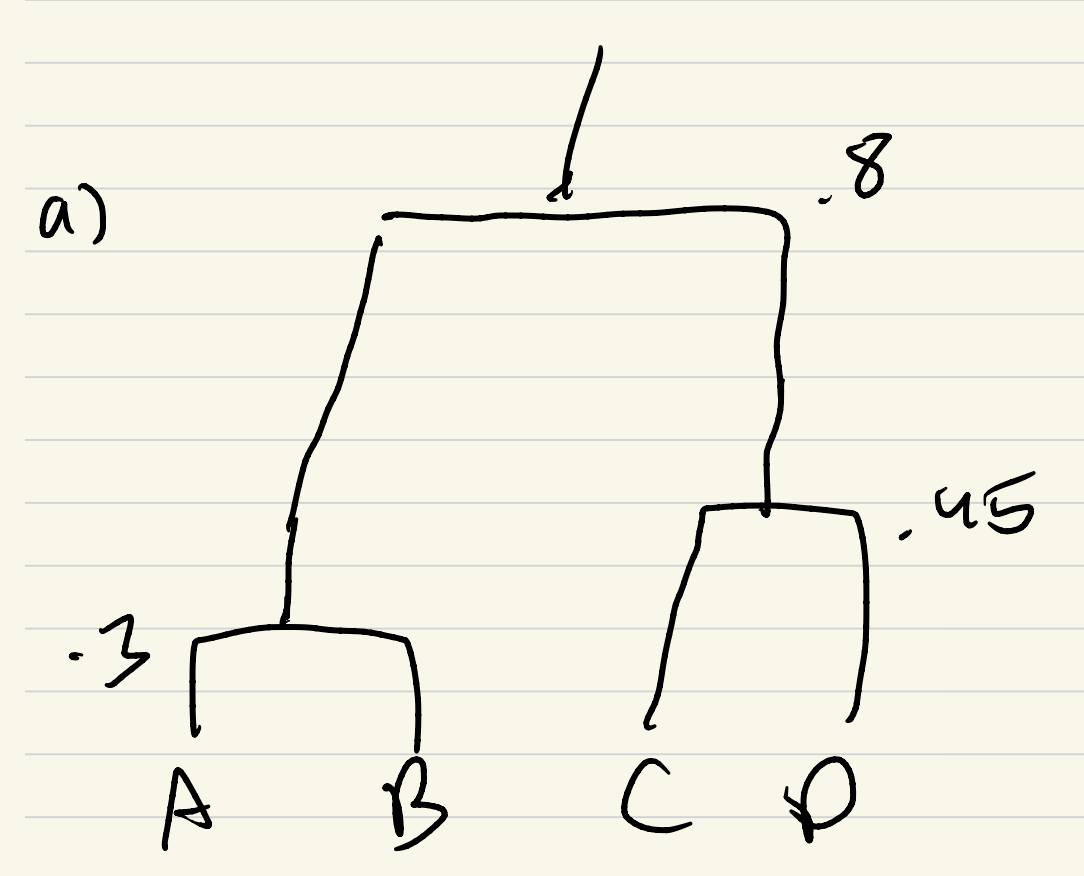

In [20]:
display(Image(filename="../images/a.png"))

### b)

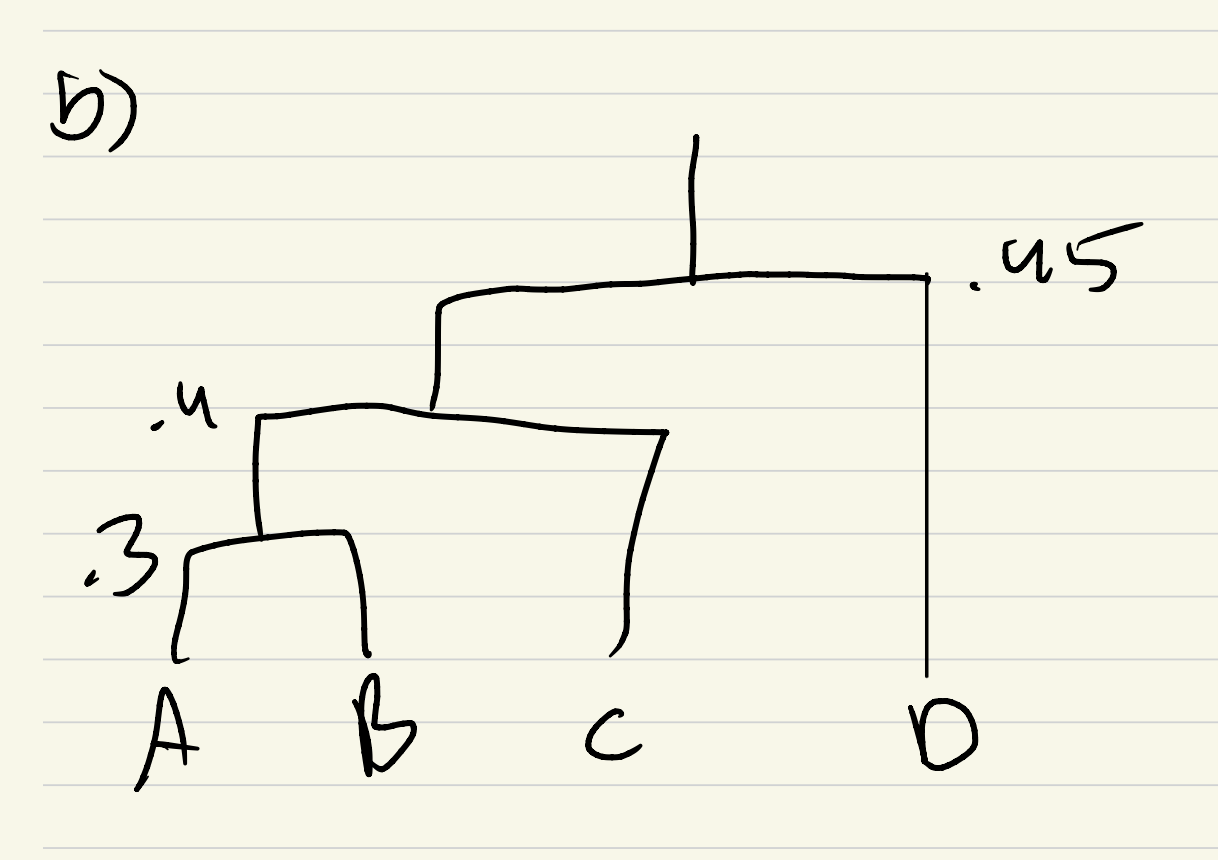

In [21]:
display(Image(filename="../images/b.png"))

### c)
We would have {A, B} and {C, D}

### d)
We would have {A, B, C} and {D}

### e)

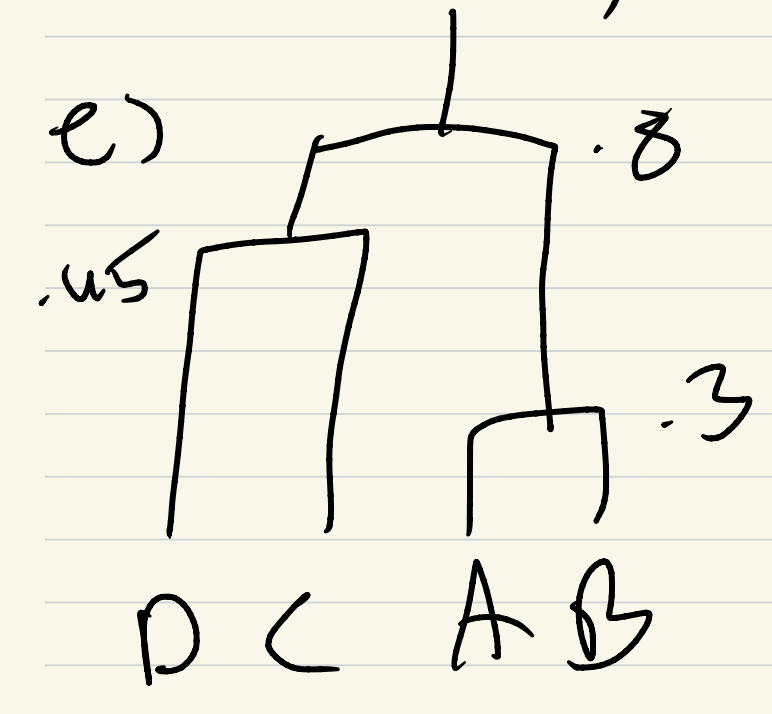

In [23]:
display(Image(filename="../images/e.png"))